# Package architecture

This page is for developers. It shows the modules of elicito,
the imports between them, and the cohesion of each subpackage.
The graph uses only the imports that run when a module loads.
The package facade `elicito/__init__.py` imports everything,
so it is not part of the graph.

The parse helpers are a copy of those in
`tests/unit/test_architecture.py`. Keep the two copies the same.

In [1]:
import ast
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown
from matplotlib.patches import Circle, FancyBboxPatch

SRC = Path(importlib.util.find_spec("elicito").origin).parent


def _module_name(path: Path) -> str:
    parts = path.relative_to(SRC.parent).with_suffix("").parts
    if parts[-1] == "__init__":
        parts = parts[:-1]
    return ".".join(parts)


FILES = {_module_name(path): path for path in sorted(SRC.rglob("*.py"))}
MODULES = sorted(name for name in FILES if name != "elicito")


def _is_type_checking(node: ast.If) -> bool:
    test = node.test
    return (isinstance(test, ast.Name) and test.id == "TYPE_CHECKING") or (
        isinstance(test, ast.Attribute) and test.attr == "TYPE_CHECKING"
    )


def _imports(module: str) -> set[str]:
    """elicito names that a module imports when it loads, not inside a function"""  # noqa: D403
    found: set[str] = set()
    body = list(ast.parse(FILES[module].read_text()).body)
    while body:
        node = body.pop()
        if isinstance(node, ast.If) and not _is_type_checking(node):
            body.extend(node.body + node.orelse)
        elif isinstance(node, ast.Try):
            body.extend(node.body + node.orelse + node.finalbody)
            for handler in node.handlers:
                body.extend(handler.body)
        elif isinstance(node, ast.Import):
            found.update(a.name for a in node.names if a.name.startswith("elicito"))
        elif isinstance(node, ast.ImportFrom) and node.module is not None:
            if node.module == "elicito" or node.module.startswith("elicito."):
                for alias in node.names:
                    # "from elicito.pkg import mod" imports the module pkg.mod
                    submodule = f"{node.module}.{alias.name}"
                    found.add(submodule if submodule in FILES else node.module)
    return found


def _ancestors(name: str) -> list[str]:
    parts = name.split(".")
    return [".".join(parts[:i]) for i in range(1, len(parts))]


def _dependencies(module: str) -> set[str]:
    """
    Modules that load when this module loads

    Importing elicito.a.b first runs the package elicito.a. A module inside
    that package is loaded by it, so that implicit edge is not counted; an
    explicit import of the package is.
    """
    own = set(_ancestors(module))
    dependencies: set[str] = set()
    for name in _imports(module):
        implicit = [a for a in _ancestors(name) if a not in own]
        dependencies.update(t for t in [*implicit, name] if t != module)
    return dependencies & set(MODULES)


def _package(module: str) -> str:
    """Top-level part below elicito: the package, or the module itself"""
    return module.split(".")[1]

## Core modules

**Entry points for the user**

- `specs`: the constructors of the user specification, such as
  `el.parameter`, `el.hyper`, `el.quantiles`, `el.correlation`,
  `el.identity`, `el.custom`, `el.partial` and `el.expert`.
- `elicit`: the `Elicit` class. It checks the input, and it has the
  methods `fit`, `sample`, `save` and `load`.
- `fit`: the results that `fit` returns: `Fit` for one expert, and
  `Panel` for a panel of experts.
- `adapter/`: the translation of a PyMC model into a generative model.

**Building blocks.** There is one block for each concept in the workflow figure.

- `parameters/`: the priors of the model parameters.
  `parametric` learns independent parametric priors.
  `deep` learns a joint prior with a normalizing flow from `networks`.
  `priors` builds the trainable prior model.
- `initializers/`: the start values of the hyperparameters.
  The methods are `exact`, `sampling` (random, lhs, sobol), `warmstart`
  and `cmaes`. `spec` holds `el.initializer`.
- `optimizers/`: the fit. `sgd` trains with a gradient-based optimizer,
  and `cmaes` runs a CMA-ES search. `search` holds the objective and
  the box that the searches share.
- `models`: the forward pass, from prior samples through the generative
  model to the elicited statistics.
- `targets`: the target quantities and the elicited statistics.
- `losses`: the discrepancy losses, such as `MMD2` and `L2`, and the
  weighted total loss.

In `parameters/` and `initializers/`, the module `methods` holds the
protocol that each method implements, and the registry of the methods.

**Support modules**

- `utils`: the expert data and small helpers.
- `_settings`: the translation of the flat settings of `Elicit` into the
  internal dictionaries.
- `_panel`: the expansion of the setup of one expert into a panel.
- `_storage`: saving an eliobj to a file, and reading it back.
- `_checks`: the checks of the user input to `Elicit`.
- `_outputs`: the `xr.DataTree` in `eliobj.results`.
- `_progress`: the progress table during training and initialization.
- `plots`: the plots of the results.
- `types` and `exceptions`: the shared types and exceptions.
  They import no other elicito module. With `_progress`, they form layer 0.

## Workflow of the Elicit object

The figure follows the conceptual workflow in the tutorials.
Each box names the concept, the elicito function that does the work,
and, in italics, the specification that the user writes.
The upper panel is one run of `Elicit.workflow(seed)`.
The loop repeats for each epoch.
The lower strip shows the public methods of the Elicit object.

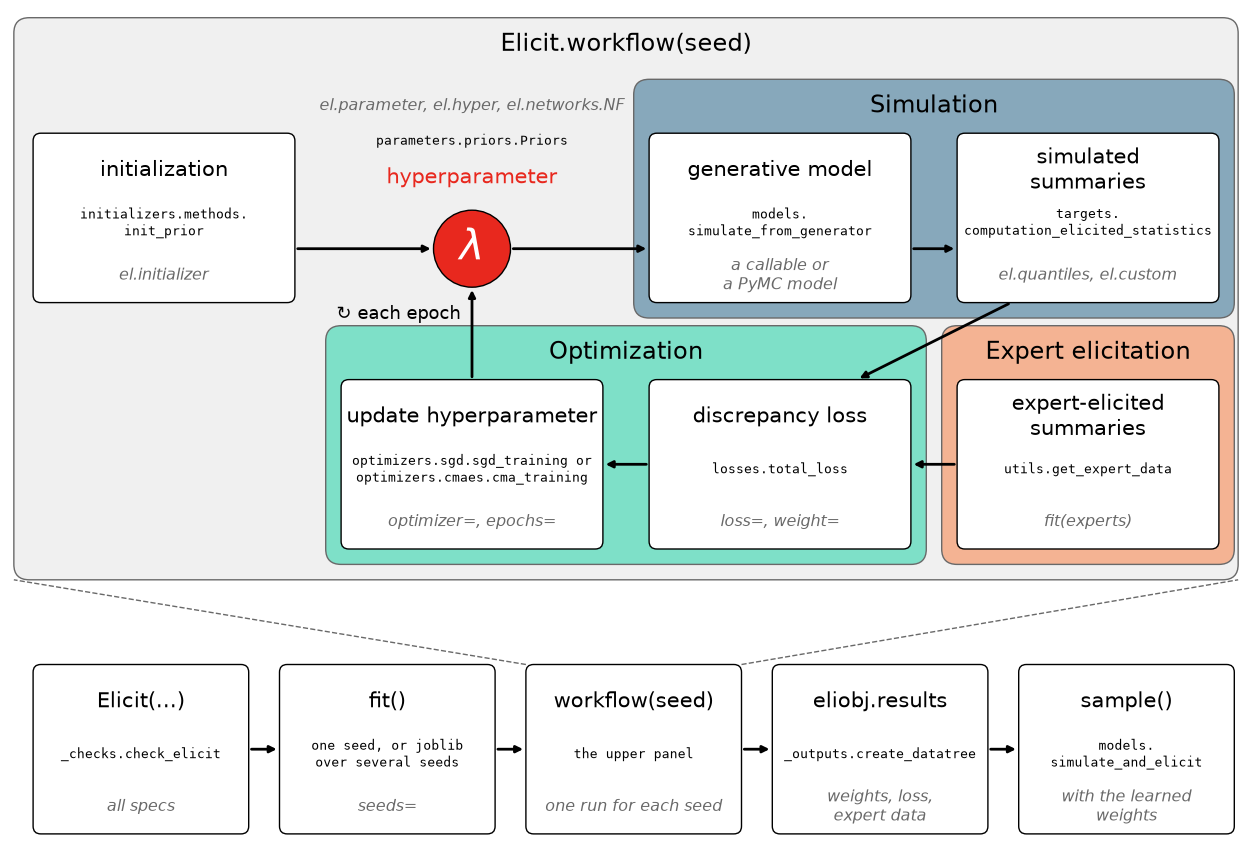

In [2]:
ORANGE = "#f4b393"
GREEN = "#7ee0c8"
BLUE = "#87a8bb"
RED = "#e8281e"
GREY = "#f0f0f0"
CODE = {"family": "monospace", "fontsize": 9.5}
SPEC = {"fontsize": 11.5, "style": "italic", "color": "dimgrey"}


def panel(ax, rect, title, face):
    """Coloured area (x, y, width, height) with a title at the top"""
    x, y, w, h = rect
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=0.2",
            facecolor=face,
            edgecolor="dimgrey",
        )
    )
    ax.text(x + w / 2, y + h - 0.35, title, ha="center", va="center", fontsize=17)


def box(ax, rect, title, code, spec):
    """White box (x, y, width, height) with the concept, function and user spec"""
    x, y, w, h = rect
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=0.1",
            facecolor="white",
            edgecolor="black",
        )
    )
    cx = x + w / 2
    ax.text(cx, y + 0.78 * h, title, ha="center", va="center", fontsize=15)
    ax.text(cx, y + 0.47 * h, code, ha="center", va="center", **CODE)
    ax.text(cx, y + 0.16 * h, spec, ha="center", va="center", **SPEC)


def arrow(ax, start, end):
    """Black arrow from start to end"""
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops={"arrowstyle": "-|>", "linewidth": 2, "color": "black"},
    )


fig, ax = plt.subplots(figsize=(16, 11))

# upper panel: one run of Elicit.workflow(seed), four columns and two rows
col = [0.3, 4.3, 8.3, 12.3]
W, H = 3.4, 2.2
TOP, BOTTOM = 7.2, 4.0
panel(ax, (0.05, 3.6, 15.9, 7.3), "Elicit.workflow(seed)", GREY)
panel(ax, (8.1, 7.0, 7.8, 3.1), "Simulation", BLUE)
panel(ax, (4.1, 3.8, 7.8, 3.1), "Optimization", GREEN)
panel(ax, (12.1, 3.8, 3.8, 3.1), "Expert elicitation", ORANGE)
box(
    ax,
    (col[0], TOP, W, H),
    "initialization",
    "initializers.methods.\ninit_prior",
    "el.initializer",
)
box(
    ax,
    (col[2], TOP, W, H),
    "generative model",
    "models.\nsimulate_from_generator",
    "a callable or\na PyMC model",
)
box(
    ax,
    (col[3], TOP, W, H),
    "simulated\nsummaries",
    "targets.\ncomputation_elicited_statistics",
    "el.quantiles, el.custom",
)
box(
    ax,
    (col[1], BOTTOM, W, H),
    "update hyperparameter",
    "optimizers.sgd.sgd_training or\noptimizers.cmaes.cma_training",
    "optimizer=, epochs=",
)
box(
    ax,
    (col[2], BOTTOM, W, H),
    "discrepancy loss",
    "losses.total_loss",
    "loss=, weight=",
)
box(
    ax,
    (col[3], BOTTOM, W, H),
    "expert-elicited\nsummaries",
    "utils.get_expert_data",
    "fit(experts)",
)
lam = (col[1] + W / 2, 7.9)
ax.add_patch(Circle(lam, 0.5, facecolor=RED, edgecolor="black"))
ax.text(*lam, r"$\lambda$", ha="center", va="center", fontsize=30, color="w")
ax.text(lam[0], 8.75, "hyperparameter", ha="center", fontsize=15, color=RED)
ax.text(lam[0], 9.25, "parameters.priors.Priors", ha="center", **CODE)
ax.text(lam[0], 9.7, "el.parameter, el.hyper, el.networks.NF", ha="center", **SPEC)

arrow(ax, (col[0] + W, lam[1]), (lam[0] - 0.5, lam[1]))
arrow(ax, (lam[0] + 0.5, lam[1]), (col[2], lam[1]))
arrow(ax, (col[2] + W, lam[1]), (col[3], lam[1]))
arrow(ax, (col[3] + 0.7, TOP), (col[2] + W - 0.7, BOTTOM + H))
arrow(ax, (col[3], 5.1), (col[2] + W, 5.1))
arrow(ax, (col[2], 5.1), (col[1] + W, 5.1))
arrow(ax, (lam[0], BOTTOM + H), (lam[0], lam[1] - 0.5))
ax.text(lam[0] - 0.15, 7.05, "↻ each epoch", ha="right", va="center", fontsize=13)

# lower strip: the public methods
steps = [
    ("Elicit(...)", "_checks.check_elicit", "all specs"),
    ("fit()", "one seed, or joblib\nover several seeds", "seeds="),
    ("workflow(seed)", "the upper panel", "one run for each seed"),
    ("eliobj.results", "_outputs.create_datatree", "weights, loss,\nexpert data"),
    (
        "sample()",
        "models.\nsimulate_and_elicit",
        "with the learned\nweights",
    ),
]
width, gap = 2.8, 0.4
for i, (title, code, spec) in enumerate(steps):
    x = 0.3 + i * (width + gap)
    box(ax, (x, 0.3, width, H), title, code, spec)
    if i:
        arrow(ax, (x - gap, 0.3 + H / 2), (x, 0.3 + H / 2))
# the workflow box of the lower strip is the upper panel
workflow_x = 0.3 + 2 * (width + gap)
for bottom, top in [(workflow_x, 0.05), (workflow_x + width, 15.95)]:
    ax.plot([bottom, top], [0.3 + H, 3.6], color="dimgrey", linewidth=1, linestyle="--")

ax.set_xlim(0, 16)
ax.set_ylim(0, 11)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

## Layers

Each node is a subpackage or a top-level module.
An arrow points from a module to a module that it imports.
A node sits one layer above the highest node that it imports.
Layer 0 imports no other elicito module.

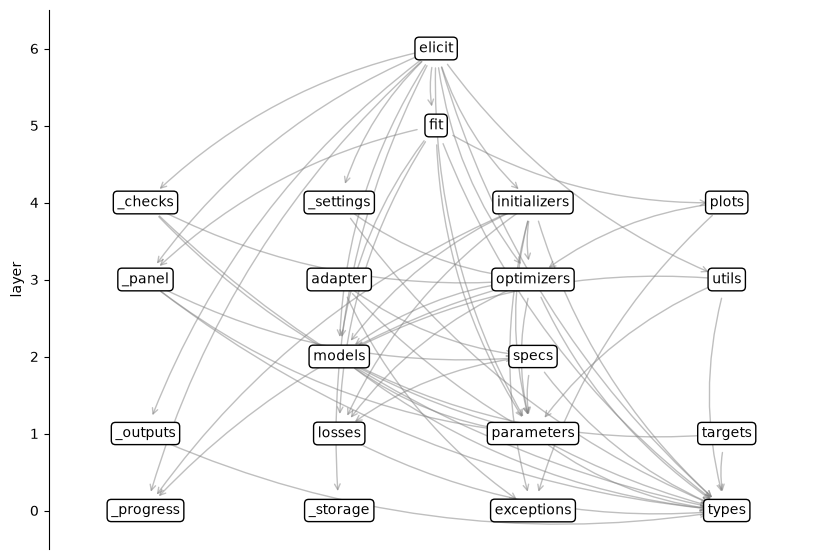

In [3]:
GRAPH = {module: _dependencies(module) for module in MODULES}
PACKAGES = sorted({_package(module) for module in MODULES})
PACKAGE_GRAPH: dict[str, set[str]] = {package: set() for package in PACKAGES}
for module, dependencies in GRAPH.items():
    PACKAGE_GRAPH[_package(module)].update(
        _package(d) for d in dependencies if _package(d) != _package(module)
    )


def layers(graph: dict[str, set[str]]) -> dict[str, int]:
    """Longest path from each node to a node with no dependency"""
    level: dict[str, int] = {}

    def visit(node: str) -> int:
        if node not in level:
            level[node] = 1 + max((visit(d) for d in graph[node]), default=-1)
        return level[node]

    for node in graph:
        visit(node)
    return level


LEVEL = layers(PACKAGE_GRAPH)
rows: dict[int, list[str]] = {}
for package in PACKAGES:
    rows.setdefault(LEVEL[package], []).append(package)
position = {
    package: (i - (len(row) - 1) / 2, level)
    for level, row in rows.items()
    for i, package in enumerate(row)
}

fig, ax = plt.subplots(figsize=(10, 7))
for package, dependencies in PACKAGE_GRAPH.items():
    for dependency in dependencies:
        ax.annotate(
            "",
            xy=position[dependency],
            xytext=position[package],
            arrowprops={
                "arrowstyle": "->",
                "color": "grey",
                "alpha": 0.5,
                "shrinkA": 14,
                "shrinkB": 14,
                "connectionstyle": "arc3,rad=0.15",
            },
        )
for package, (x, y) in position.items():
    ax.text(
        x,
        y,
        package,
        ha="center",
        va="center",
        bbox={"boxstyle": "round", "facecolor": "white"},
    )
width = max(len(row) for row in rows.values()) / 2
ax.set_xlim(-width, width)
ax.set_ylim(-0.5, max(rows) + 0.5)
ax.set_yticks(sorted(rows))
ax.set_ylabel("layer")
ax.set_xticks([])
ax.spines[["top", "right", "bottom"]].set_visible(False)
plt.show()

## Dependency structure matrix

A dark cell in row A and column B means: module A imports module B.
The blue lines separate the subpackages.
The order follows the layers, so all cells lie below the diagonal.
A cell above the diagonal would show an import cycle.

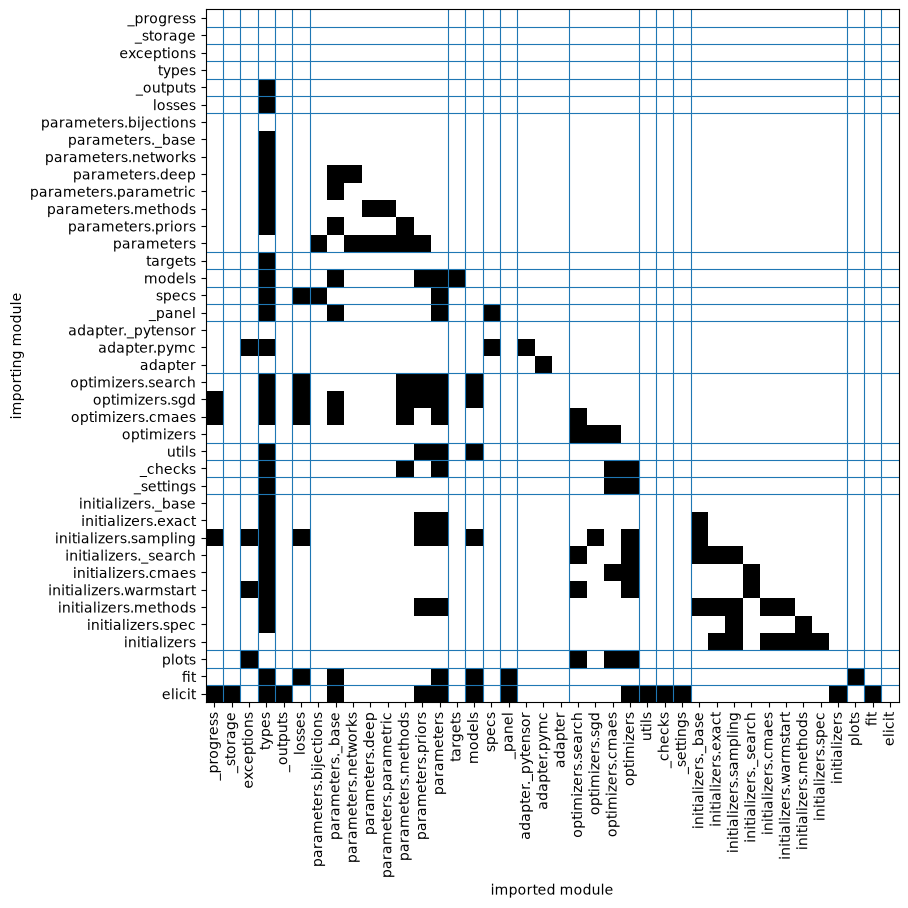

In [4]:
MODULE_LEVEL = layers(GRAPH)
ORDER = sorted(
    MODULES,
    key=lambda m: (LEVEL[_package(m)], _package(m), MODULE_LEVEL[m], m),
)
index = {module: i for i, module in enumerate(ORDER)}
matrix = np.zeros((len(ORDER), len(ORDER)))
for module, dependencies in GRAPH.items():
    for dependency in dependencies:
        matrix[index[module], index[dependency]] = 1

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(matrix, cmap="Greys", vmin=0, vmax=1)
labels = [module.removeprefix("elicito.") for module in ORDER]
ax.set_xticks(range(len(ORDER)), labels, rotation=90)
ax.set_yticks(range(len(ORDER)), labels)
for i in range(1, len(ORDER)):
    if _package(ORDER[i]) != _package(ORDER[i - 1]):
        ax.axhline(i - 0.5, color="tab:blue", linewidth=0.8)
        ax.axvline(i - 0.5, color="tab:blue", linewidth=0.8)
ax.set_xlabel("imported module")
ax.set_ylabel("importing module")
plt.show()

## Cohesion and coupling

The table counts the module imports for each node of the layer plot.

- *internal*: imports between the modules of the node.
- *outgoing*: imports from the node to other nodes.
- *incoming*: imports from other nodes into the node.
- *cohesion* is internal / (internal + outgoing).
  A high value means that the modules of the node work mostly together.
- *instability* is outgoing / (incoming + outgoing), after Robert C. Martin.
  A value of 0 means that other nodes depend on it, and it depends on none.

In [5]:
lines = [
    "| node | modules | internal | outgoing | incoming | cohesion | instability |",
    "| :-- | --: | --: | --: | --: | --: | --: |",
]
INSTABILITY: dict[str, float] = {}
for package in sorted(PACKAGES, key=lambda p: (LEVEL[p], p)):
    members = [m for m in MODULES if _package(m) == package]
    internal = sum(_package(d) == package for m in members for d in GRAPH[m])
    outgoing = sum(_package(d) != package for m in members for d in GRAPH[m])
    incoming = sum(
        _package(d) == package
        for m in MODULES
        if _package(m) != package
        for d in GRAPH[m]
    )
    cohesion = f"{internal / (internal + outgoing):.2f}" if len(members) > 1 else "-"
    coupled = incoming + outgoing
    if coupled:
        INSTABILITY[package] = outgoing / coupled
    instability = f"{INSTABILITY[package]:.2f}" if coupled else "-"
    lines.append(
        f"| `{package}` | {len(members)} | {internal} | {outgoing} "
        f"| {incoming} | {cohesion} | {instability} |"
    )
Markdown("\n".join(lines))

| node | modules | internal | outgoing | incoming | cohesion | instability |
| :-- | --: | --: | --: | --: | --: | --: |
| `_progress` | 1 | 0 | 0 | 4 | - | 0.00 |
| `_storage` | 1 | 0 | 0 | 1 | - | 0.00 |
| `exceptions` | 1 | 0 | 0 | 4 | - | 0.00 |
| `types` | 1 | 0 | 0 | 29 | - | 0.00 |
| `_outputs` | 1 | 0 | 1 | 1 | - | 0.50 |
| `losses` | 1 | 0 | 1 | 6 | - | 0.14 |
| `parameters` | 8 | 13 | 6 | 32 | 0.68 | 0.16 |
| `targets` | 1 | 0 | 1 | 1 | - | 0.50 |
| `models` | 1 | 0 | 5 | 6 | - | 0.45 |
| `specs` | 1 | 0 | 4 | 2 | - | 0.67 |
| `_panel` | 1 | 0 | 4 | 2 | - | 0.67 |
| `adapter` | 3 | 2 | 3 | 0 | 0.40 | 1.00 |
| `optimizers` | 4 | 4 | 20 | 16 | 0.17 | 0.56 |
| `utils` | 1 | 0 | 4 | 1 | - | 0.80 |
| `_checks` | 1 | 0 | 5 | 1 | - | 0.83 |
| `_settings` | 1 | 0 | 3 | 1 | - | 0.75 |
| `initializers` | 9 | 20 | 27 | 1 | 0.43 | 0.96 |
| `plots` | 1 | 0 | 4 | 1 | - | 0.80 |
| `fit` | 1 | 0 | 7 | 1 | - | 0.88 |
| `elicit` | 1 | 0 | 15 | 0 | - | 1.00 |

## Stable dependencies

A good instability value depends on the role of the node.
A base node, such as `types`, has many incoming imports.
Its instability should be near 0, because many nodes break if it changes.
A top node, such as `elicit`, has no incoming imports.
Its instability can be near 1, because you can change it freely.

The Stable Dependencies Principle of Robert C. Martin gives a rule to check:
a node should import only nodes with an instability that is not higher.
The table lists each import that breaks this rule.
Such an import makes a node depend on a node that changes more often.

In [6]:
violations = [
    f"| `{package}` | `{dependency}` "
    f"| {INSTABILITY[package]:.2f} | {INSTABILITY[dependency]:.2f} |"
    for package in PACKAGES
    for dependency in sorted(PACKAGE_GRAPH[package])
    if INSTABILITY[dependency] > INSTABILITY[package]
]
header = [
    "| node | imports | instability of the node | instability of the import |",
    "| :-- | :-- | --: | --: |",
]
if violations:
    result = Markdown("\n".join(header + violations))
else:
    result = Markdown("No import goes to a less stable node.")
result

| node | imports | instability of the node | instability of the import |
| :-- | :-- | --: | --: |
| `models` | `targets` | 0.45 | 0.50 |